         Date    Product  Sales  Quantity Region
0  2023-01-01  Product A    200         4  North
1  2023-01-02  Product B    150         3  South
2  2023-01-03  Product A    220         5  North
3  2023-01-04  Product C    300         6   East
4  2023-01-05  Product B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales   Quantity
count   16.000000  16.000000
mean   237.500000   5.062500
std     64.031242   1.526161
min    150.000000   3.000000
25%    187.500000   4.000000
50%    225.000000   5.000000
75%    302.500000   6.000000
max    340.000000   8.000000
     Product  Sales  Quantity
0  Product A   1350        30
1  Product B    850        17
2  Product C   1600        34


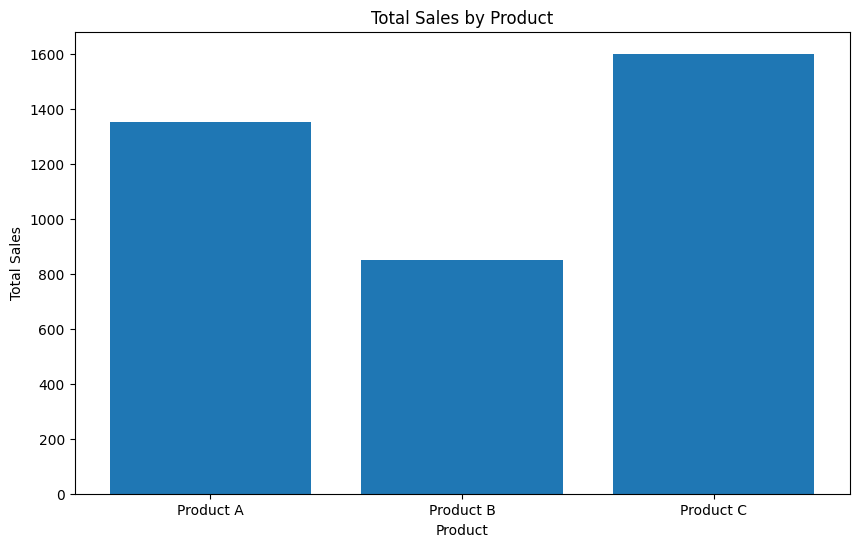

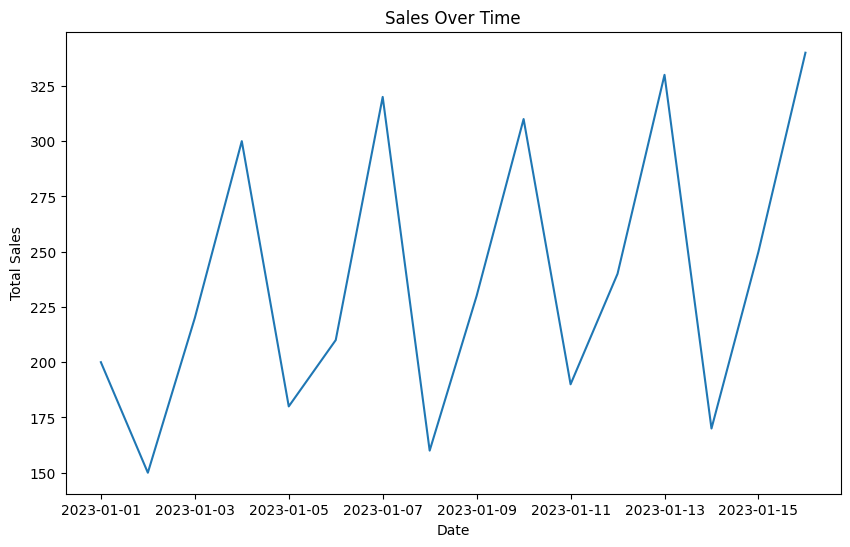

Product  Product A  Product B  Product C
Region                                  
East             0          0       1600
North         1350          0          0
South            0        150          0
West             0        700          0
             Sales  Quantity
Sales     1.000000  0.956796
Quantity  0.956796  1.000000


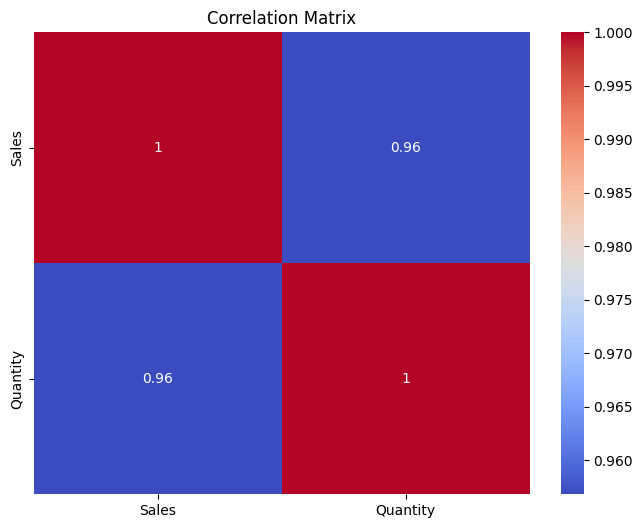

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = {
    'Date': [
        '2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
        '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
        '2023-01-09', '2023-01-10', '2023-01-11', '2023-01-12',
        '2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16'
    ],
    'Product': [
        'Product A', 'Product B', 'Product A', 'Product C',
        'Product B', 'Product A', 'Product C', 'Product B',
        'Product A', 'Product C', 'Product B', 'Product A',
        'Product C', 'Product B', 'Product A', 'Product C'
    ],
    'Sales': [
        200, 150, 220, 300, 180, 210, 320, 160,
        230, 310, 190, 240, 330, 170, 250, 340
    ],
    'Quantity': [
        4, 3, 5, 6, 4, 5, 7, 3,
        5, 6, 4, 5, 8, 3, 6, 7
    ],
    'Region': [
        'North', 'South', 'North', 'East',
        'West', 'North', 'East', 'West',
        'North', 'East', 'West', 'North',
        'East', 'West', 'North', 'East'
    ]
}
df = pd.DataFrame(data)
df.to_csv('sales_data.csv', index=False)
print(df.head())
print(df.isnull().sum())
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)
print(df.describe())
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()
print(product_summary)
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()
df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({
    'Sales': 'sum'
}).reset_index()
plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.show()
pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc='sum',
    fill_value=0
)
print(pivot_table)
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()